# 07 -- Full galaxy analysis, start to finish

A complete kinematic extraction of a real IFU cube, the NGC 4751 MUSE NFM data, from masks to maps:
1. masks and the legacy dartboard;
2. one spectrum per bin;
3. fits with the package defaults (fixed `lam`, raised for broad bins);
4. error bands from the sky-line + template-mismatch noise model;
5. diagnostics and hand tuning;
6. example fits;
7. systemic velocity;
8. moment maps and radial profiles;
9. a mirror-symmetry check of the errors.

It builds on `04_template_calibration.ipynb` (the template subset and radial profile), `02_realistic_mock_fit.ipynb`
(Section 5b, the `lam` rule) and `05_noise_correlation.ipynb` (Section 8, the noise model). The method is validated in
`dev_notes/regularization_v2/FINDINGS.md`.

**Run modes.** By default (`FORCE_RECOMPUTE = False`) every section reads `../data/muse/ngc4751_nfm_full_galaxy_results.npz`,
the compact output of a full run of this notebook, so it runs in seconds without the cube. With
`FORCE_RECOMPUTE = True` it needs the 3.3 GB cube (downloaded by `04_template_calibration.ipynb`) and takes about
15 minutes on 4 cores; the last cell then rewrites the shipped file.

In [1]:
from __future__ import annotations
import time
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from cmap import Colormap                       # pip install cmap (the examples extra): cmasher's colormaps

from kinextract import (
    FitConfig, assign_legacy_dartboard_bins, build_template_stack, combine_bin_spectrum_robust, compute_losvd_moments,
    detect_emission_lines, edge_amplitude_frac, fit_losvd_robust_parallel, full_pixel_model, load_emiles_templates,
    load_legacy_bin_edges, load_muse_cube, load_muse_sky_lines, losvd_error_bands_parallel, mask_wavelength_windows,
    sky_line_profile, white_light_image, whiten,
)
from kinextract.template_reduction import load_template_subset

# ---- data
CUBE_PATH = "muse_download/ADP.2022-12-13T15:54:49.001.fits"           # NGC 4751 MUSE NFM (04 downloads it)
SKY_LINES_PATH = "muse_download/MU_GSKL_140101A_sky_lines.fits"         # MUSE pipeline sky-line catalog (1 MB)
SKY_LINES_URL = "https://dataportal.eso.org/dataportal_new/file/M.MUSE.2023-07-03T08:28:46.633"
TEMPLATE_SUBSET_PATH = "../data/muse/ngc4751_template_subset.npz"       # 04_template_calibration.ipynb
RADIAL_KIN_PATH = "../data/muse/ngc4751_radial_kinematics.npz"          # 04_template_calibration.ipynb
BIN_R_PATH, BIN_V_PATH = "../data/muse/ngc4751_bin_r.out", "../data/muse/ngc4751_bin_v.out"   # the legacy dartboard
EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
RESULTS_PATH = Path("../data/muse/ngc4751_nfm_full_galaxy_results.npz")
FORCE_RECOMPUTE = False

# ---- geometry
Z = 0.006985
PA_NE = 174.7                # kinematic major axis, deg E of N (constant from 0.03" to 10" in this galaxy)
CENTER_YX = (169, 180)       # binning center: the brightest spaxel
MAX_RING = 12                # the NFM's ring 13 (5.2") is the field corners, mostly edge spaxels
BAD_SPAXELS = tuple((y, 169) for y in range(160, 179)) + ((161, 171), (163, 171), (164, 170), (165, 177),
                                                          (171, 168), (174, 175))
# ^ defective spectra (a stripe at x = 169 and isolated spaxels): red-skewed LOSVDs 300-500 km/s off their
#   neighbors; the cube was reduced without a bad-pixel table, so nothing flags them in the data

# ---- fitting
WAVEFITMIN, WAVEFITMAX = 8300.0, 8850.0
SPATIAL_RHO = 0.146          # spaxel-to-spaxel correlation of this cube, for combining spaxels
FALLBACK_RHO, MIN_SPAXELS_RHO = 0.708, 20     # bins with fewer spaxels use this pixel correlation
N_JOBS, BATCH = 4, 16

USE_SHIPPED = RESULTS_PATH.exists() and not FORCE_RECOMPUTE
print("using the shipped results" if USE_SHIPPED else "full run")

using the shipped results


## 1. Masks and bins

- **The straight cut:** every spaxel on the dusty side of the kinematic major axis is left out (below).
- **Defective spaxels:** masked too.
- **Binning:** the remaining spaxels go into a legacy polar dartboard (`bin_r.out`/`bin_v.out`).
  - It folds about the major axis, so each bin is two mirror-image wedges.
  - `bin` and `bnn` bins sit on the two sides of the minor axis.

**Why half of the cube is masked: the dust disk.** NGC 4751 has a prominent dust disk, seen nearly edge-on
(inclination about 79 degrees), lying along its kinematic major axis (KMA). On one side of the major axis the disk
is in front of the bulge, and its dust absorbs and reddens the light of the stars behind it. A spectrum there is
dominated by the stars in front of the dust: its LOSVD is not the full line-of-sight velocity distribution, its
continuum is reddened, and its apparent stellar population is wrong. The dust is too patchy and too optically thick
to correct reliably. The other side of the major axis is dust-free, and in an axisymmetric galaxy the kinematics are
mirror-symmetric about the major axis, so the dust-free half carries the same kinematic information. Every spaxel
on the dusty side is therefore excluded rather than corrected.

The cut is a straight line along the major axis (`PA_NE`) through the nucleus. Because the dartboard folds about the
major axis, each bin's two mirror-image wedges are one on each side of it, so the kept half still fills every bin.

102 bins (52 bin + 50 bnn), rings 1-12 (r < 4.16")


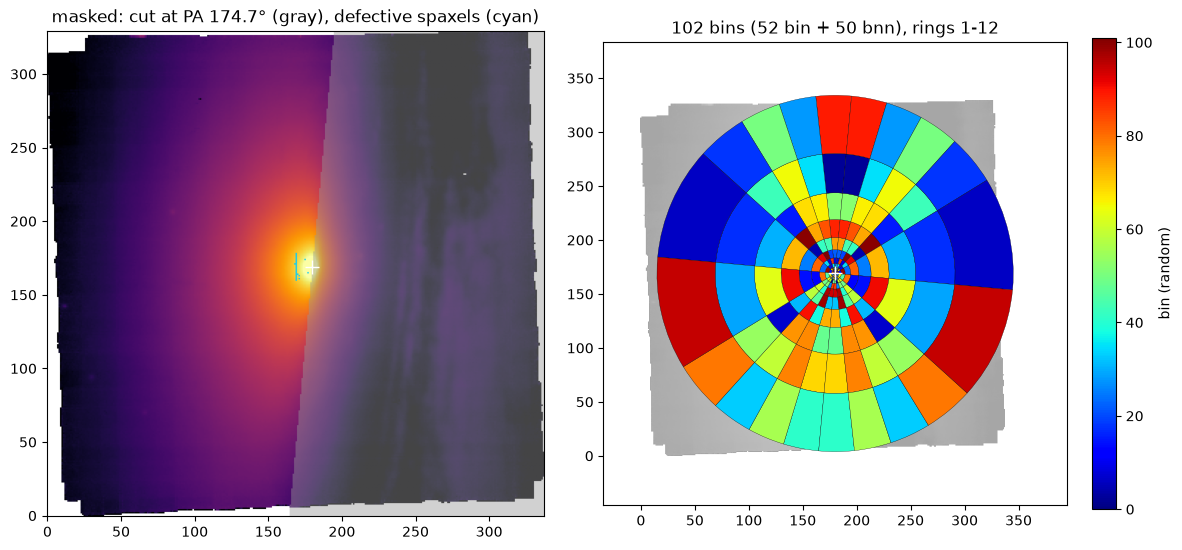

In [2]:
r_edges, v_edges = load_legacy_bin_edges(BIN_R_PATH, BIN_V_PATH)
r_edges = r_edges[: MAX_RING + 1]
cy, cx = CENTER_YX

if USE_SHIPPED:
    S = np.load(RESULTS_PATH)
    white, mask, bin_map, pix = S["white"], S["mask"], S["bin_map"], float(S["pix"])
    table = [dict(bin_id=int(i), bin_name=str(n), irc=int(rc), irv=int(rv), side=int(sd), r_mid=float(r))
             for i, n, rc, rv, sd, r in zip(S["bin_id"], S["bin_name"], S["irc"], S["irv"], S["side"], S["r_mid"])]
else:
    cube = load_muse_cube(CUBE_PATH)
    pix = float(cube.pixel_scale)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        white = white_light_image(cube)
        signal, noise = np.nanmedian(cube.flux, axis=0), np.nanmedian(cube.error, axis=0)
    yy, xx = np.mgrid[:cube.shape[0], :cube.shape[1]]
    t = np.radians(PA_NE)
    mask = ((xx - cx) * np.cos(t) + (yy - cy) * np.sin(t)) < 0          # the dusty side of the major axis
    for y, x in BAD_SPAXELS:
        mask[y, x] = True
    good = np.isfinite(signal) & np.isfinite(noise) & (signal > 0) & (noise > 0) & ~mask
    cube.flux[:, ~good] = np.nan
    cube.error[:, ~good] = np.nan
    bin_map, table = assign_legacy_dartboard_bins(cube.shape, center=(cx, cy), pa_deg=PA_NE - 90.0, r_edges=r_edges,
                                                  v_edges_deg=v_edges, pixel_scale=pix)
    bin_map[~good] = -1
    table = [row for row in table if np.any(bin_map == row["bin_id"])]
print(f"{len(table)} bins ({sum(r['side'] > 0 for r in table)} bin + {sum(r['side'] < 0 for r in table)} bnn), "
      f"rings 1-{max(r['irc'] for r in table)} (r < {r_edges[-1]:.2f}\")")


def draw_bins(ax, rows, values, cmap, norm, origin=(0.0, 0.0), unit=1.0, pa=PA_NE - 90.0, lw=0.3, axis_line=True):
    """Each bin at its real footprint: two mirror-image wedges per bin. origin (x, y) and unit (arcsec per plot unit):
    (0, 0) and 1 for maps in arcsec from the center, the center pixel and the pixel scale over an image."""
    ox, oy = origin
    for row in rows:
        r0, r1 = r_edges[row["irc"] - 1] / unit, r_edges[row["irc"]] / unit
        a0, a1 = v_edges[row["irv"] - 1], v_edges[row["irv"]]
        rngs = [(a0, a1), (-a1, -a0)] if row["side"] > 0 else [(180 - a1, 180 - a0), (180 + a0, 180 + a1)]
        for t0, t1 in rngs:
            ax.add_patch(mpatches.Wedge((ox, oy), r1, t0 + pa, t1 + pa, width=r1 - r0,
                                        facecolor=cmap(norm(values[row["bin_name"]])), edgecolor="k", lw=lw))
    if axis_line:
        rmax, th = r_edges[-1] / unit, np.radians(pa)
        ax.plot([ox - rmax * np.cos(th), ox + rmax * np.cos(th)], [oy - rmax * np.sin(th), oy + rmax * np.sin(th)],
                "w:", lw=1.2, alpha=0.7)
    ax.set_aspect("equal")


bad = np.zeros(white.shape, bool)
for y, x in BAD_SPAXELS:
    bad[y, x] = True
cut = mask & ~bad
with np.errstate(divide="ignore", invalid="ignore"):
    log_white = np.log10(np.where(white > 0, white, np.nan))
lo, hi = np.nanpercentile(log_white, [5, 99.9])      # clip the faint field edges, or they flatten the stretch
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
ax[0].imshow(log_white, origin="lower", cmap="inferno", vmin=lo, vmax=hi)
overlay = np.zeros(white.shape + (4,))
overlay[cut] = (0.6, 0.6, 0.6, 0.45)
overlay[bad] = (0.0, 0.8, 1.0, 0.9)
ax[0].imshow(overlay, origin="lower")
ax[0].set_title(f"masked: cut at PA {PA_NE}° (gray), defective spaxels (cyan)")
ax[1].imshow(log_white, origin="lower", cmap="gray", vmin=lo, vmax=hi, alpha=0.35)
norm = plt.Normalize(0, len(table) - 1)
rng = np.random.default_rng(0)
draw_bins(ax[1], table, {r["bin_name"]: v for r, v in zip(table, rng.permutation(len(table)))}, plt.get_cmap("jet"),
          norm, origin=(cx, cy), unit=pix, lw=0.2, axis_line=False)
plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="jet"), ax=ax[1], fraction=0.046, label="bin (random)")
R = 1.3 * r_edges[-1] / pix
ax[1].set_xlim(cx - R, cx + R); ax[1].set_ylim(cy - R, cy + R)
ax[1].set_title(f"{len(table)} bins ({sum(r['side'] > 0 for r in table)} bin + {sum(r['side'] < 0 for r in table)} bnn), "
                f"rings 1-{max(r['irc'] for r in table)}")
for a in ax:
    a.plot(cx, cy, "w+", ms=10)
plt.tight_layout(); plt.show()

## 2. One spectrum per bin

- **Combining spaxels:** `combine_bin_spectrum_robust` makes a biweight mean of each bin's spaxels, with errors that
  account for the cube's spatial correlation (`SPATIAL_RHO`).
- **The fit window:** each spectrum is cut to the CaT window in the rest frame.
- **Emission lines:** detected and masked per bin.
- **The velocity grid:** one grid for every bin, the central V ± 5σ from 04's radial profile.

In [3]:
subset = load_template_subset(TEMPLATE_SUBSET_PATH)
u = subset["union_selected"]
templates, twave, *_ = load_emiles_templates(EMILES_GRID, select=list(zip(subset["template_ages"][u].tolist(),
                                                                            subset["template_metals"][u].tolist())))
rk = np.load(RADIAL_KIN_PATH)
i0 = int(np.argmin(np.abs(rk["r_mid"])))
VMIN, VMAX = float(rk["vherm"][i0] - 5 * rk["sherm"][i0]), float(rk["vherm"][i0] + 5 * rk["sherm"][i0])


def cfg_for(rho=0.0, lam=None):
    """The package defaults on this grid; `lam` set -> exactly that lam (a hand override, no lam rule)."""
    if lam is None:
        return FitConfig(vmin=VMIN, vmax=VMAX, rho=rho)
    return FitConfig(vmin=VMIN, vmax=VMAX, rho=rho, lam=float(lam), lam_rule="fixed")


V_GRID = cfg_for().build_velocity_grid()
print(f"{len(templates)} templates; velocity grid {VMIN:.0f} to {VMAX:.0f} km/s ({len(V_GRID)} points)")

if not USE_SHIPPED:
    bins = []
    for row in table:
        sel = bin_map == row["bin_id"]
        wo, fo, eo = combine_bin_spectrum_robust(cube, sel, variance_correction_factor=1.0, spatial_rho=SPATIAL_RHO)
        wr = wo / (1 + Z)
        w = (wr >= WAVEFITMIN) & (wr <= WAVEFITMAX)
        em = detect_emission_lines(wr[w], fo[w], eo[w])
        wave, flux = mask_wavelength_windows(wr[w], fo[w], windows=em)
        _, err = mask_wavelength_windows(wr[w], eo[w], windows=em)
        bins.append(dict(row, n_spaxels=int(sel.sum()), wave=wave, flux=flux, err=err))
    del cube
    print(f"{len(bins)} spectra, S/N {np.median([np.median(b['flux'] / b['err']) for b in bins]):.0f} (median)")

35 templates; velocity grid -2702 to 2856 km/s (695 points)


## 3. Fits: the package defaults

`fit_losvd_robust` with a default `FitConfig` on the shared grid does the whole recipe for each bin:
- **Regularization:** `lam = 4096`; bins broader than 350 km/s are refitted at `sigma_scaled_lam(sigma)` =
  4096 (sigma/350)^6, capped at 131072, and a fit still holding more than 1 % of its peak at the grid edge is retried
  at 2x, then a further 4x, its `lam` (`FitConfig.lam_rule`; `02_realistic_mock_fit.ipynb`, Section 5b).
- **The continuum** is co-fitted.
- **Cleaning:** errors are inflated where the residuals call for it, with the CaT cores protected from clipping.

Bins with at least 20 spaxels measure their own pixel correlation (`measure_rho=True`); smaller ones use the
cube's typical value, `FALLBACK_RHO`.

In [4]:
def fit(sel, lams=None):
    """fit_losvd_robust_parallel on the bins in `sel`, with the defaults, or at lams[bin_name] (hand overrides)."""
    for big in (True, False):                                    # big bins measure their own pixel correlation
        grp = [b for b in sel if (b["n_spaxels"] >= MIN_SPAXELS_RHO) == big]
        for k in range(0, len(grp), BATCH):
            chunk = grp[k:k + BATCH]
            cfgs = [cfg_for(0.0 if big else FALLBACK_RHO, None if lams is None else lams[b["bin_name"]]) for b in chunk]
            A = [build_template_stack(b["wave"], twave, templates, V_GRID) for b in chunk]
            res = fit_losvd_robust_parallel(A, [b["flux"] for b in chunk], [b["err"] for b in chunk], cfgs,
                                            wave_fit_list=[b["wave"] for b in chunk], n_jobs=N_JOBS, measure_rho=big)
            for b, r in zip(chunk, res):
                b["fit"] = r
                b["edge"] = float(edge_amplitude_frac(r["b"]))


if not USE_SHIPPED:
    t0 = time.time()
    fit(bins)
    print(f"fitted {len(bins)} bins in {time.time() - t0:.0f} s")

## 4. Error bands: the sky-line + template-mismatch noise model

`losvd_error_bands_parallel` runs the recipe of `05_noise_correlation.ipynb`, Section 8, for every bin:
1. **The noise model:** err^2 + (kappa s)^2 + (f model)^2, fitted to the residuals of a preliminary `lam = 4096` fit,
   with s the LSF-blended MUSE sky-line spectrum.
2. **The Laplace posterior:** with those errors (times the robust fit's own inflation), at the bin's `lam` and
   `rho`, without its clipped pixels.
3. **Re-centering:** the draws are moved onto the plain-error fit.

The moment errors are half the 16-84 % range of the moments of 100 draws.

In [5]:
def moments_of(v, b):
    m = compute_losvd_moments(v, b, fit_h3h4=True)
    return [m["vherm"], m["sherm"], m["h3"], m["h4"]]


def bands(sel):
    if not Path(SKY_LINES_PATH).exists():
        Path(SKY_LINES_PATH).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(SKY_LINES_URL, SKY_LINES_PATH)
    lw, lf = load_muse_sky_lines(SKY_LINES_PATH)
    for k in range(0, len(sel), BATCH):
        chunk = sel[k:k + BATCH]
        out = losvd_error_bands_parallel(
            [build_template_stack(b["wave"], twave, templates, V_GRID) for b in chunk], [b["flux"] for b in chunk],
            [b["err"] for b in chunk], [b["wave"] for b in chunk], [b["fit"] for b in chunk], cfg_for(),
            sky_profile_list=[sky_line_profile(b["wave"], lw, lf, z=Z) for b in chunk], n_jobs=N_JOBS, seed=k)
        for b, o in zip(chunk, out):
            b["band"], b["inflation"] = o, o["inflation"]
            b["merr"] = [o["vherm_err"], o["sherm_err"], o["h3_err"], o["h4_err"]]


if not USE_SHIPPED:
    t0 = time.time()
    bands(bins)
    print(f"bands for {len(bins)} bins in {time.time() - t0:.0f} s; median error inflation "
          f"{np.median([b['inflation'] for b in bins]):.2f}")

## 5. Diagnostics and hand tuning

The table below collects every bin's moments and errors, one row per bin. Two kinds of bin are flagged for a look:
- **Edge fits:** fits still at the grid edge after the retries.
- **Ring outliers:** sigma or h4 more than 3 robust MAD from the median of the bin's ring.

Then:
- **`LAM_OVERRIDE`** refits a bin at a `lam` of your choice, with new bands.
- **`REVIEW`** approves or rejects bins. Rejected bins are left out of V_sys, the maps and the profiles.

In [6]:
if USE_SHIPPED:
    kin = {k: S[k] for k in ("bin_name", "irc", "irv", "side", "r_mid", "n_spaxels", "lam", "edge", "inflation",
                             "V", "sigma", "h3", "h4", "eV", "esigma", "eh3", "eh4")}
else:
    kin = dict(bin_name=np.array([b["bin_name"] for b in bins]), irc=np.array([b["irc"] for b in bins]),
               irv=np.array([b["irv"] for b in bins]), side=np.array([b["side"] for b in bins]),
               r_mid=np.array([abs(b["r_mid"]) for b in bins]), n_spaxels=np.array([b["n_spaxels"] for b in bins]),
               lam=np.array([b["fit"]["lam_used"] for b in bins]), edge=np.array([b["edge"] for b in bins]),
               inflation=np.array([b["inflation"] for b in bins]))
    for i, k in enumerate(("V", "sigma", "h3", "h4")):
        kin[k] = np.array([moments_of(V_GRID, b["fit"]["b"])[i] for b in bins])
        kin["e" + k] = np.array([b["merr"][i] for b in bins])
lam = kin["lam"]
lam0 = FitConfig().lam
print(f"lam: {np.sum(lam == lam0)} bins at {lam0:.0f}, {np.sum(lam > lam0)} raised (max {lam.max():.0f}); "
      f"median error inflation {np.median(kin['inflation']):.2f}")
for i in np.flatnonzero(kin["edge"] > FitConfig().max_edge_amplitude_frac):
    print(f"at the grid edge: {kin['bin_name'][i]}")
for ring in np.unique(kin["irc"]):
    s = kin["irc"] == ring
    for key, floor in (("sigma", 0.05), ("h4", None)):
        med = np.median(kin[key][s])
        mad = max(1.4826 * np.median(np.abs(kin[key][s] - med)), floor * med if floor else 0.01)
        for i in np.flatnonzero(s & (np.abs(kin[key] - med) > 3 * mad)):
            print(f"ring outlier: {kin['bin_name'][i]} {key} {kin[key][i]:.3g} (ring median {med:.3g})")

lam: 42 bins at 4096, 60 raised (max 131072); median error inflation 1.34
ring outlier: bin0801 sigma 420 (ring median 347)
ring outlier: bnn0901 sigma 379 (ring median 322)
ring outlier: bnn1101 sigma 338 (ring median 247)
ring outlier: bnn1205 sigma 306 (ring median 231)


In [7]:
LAM_OVERRIDE = {}      # bin_name -> lam, e.g. {"bin0105": 8192.0}
REVIEW = {}            # bin_name -> "approve" | "reject"

if LAM_OVERRIDE and not USE_SHIPPED:
    sel = [b for b in bins if b["bin_name"] in LAM_OVERRIDE]
    fit(sel, LAM_OVERRIDE)
    bands(sel)
    for b in sel:
        i = int(np.flatnonzero(kin["bin_name"] == b["bin_name"])[0])
        kin["lam"][i] = b["fit"]["lam_used"]
        for j, k in enumerate(("V", "sigma", "h3", "h4")):
            kin[k][i], kin["e" + k][i] = moments_of(V_GRID, b["fit"]["b"])[j], b["merr"][j]
kept = np.array([REVIEW.get(n) != "reject" for n in kin["bin_name"]])
print(f"{kept.sum()} of {len(kept)} bins kept")

102 of 102 bins kept


## 6. Example fits

A few bins from the center outward: the spectrum and fit, and the LOSVD with its band.

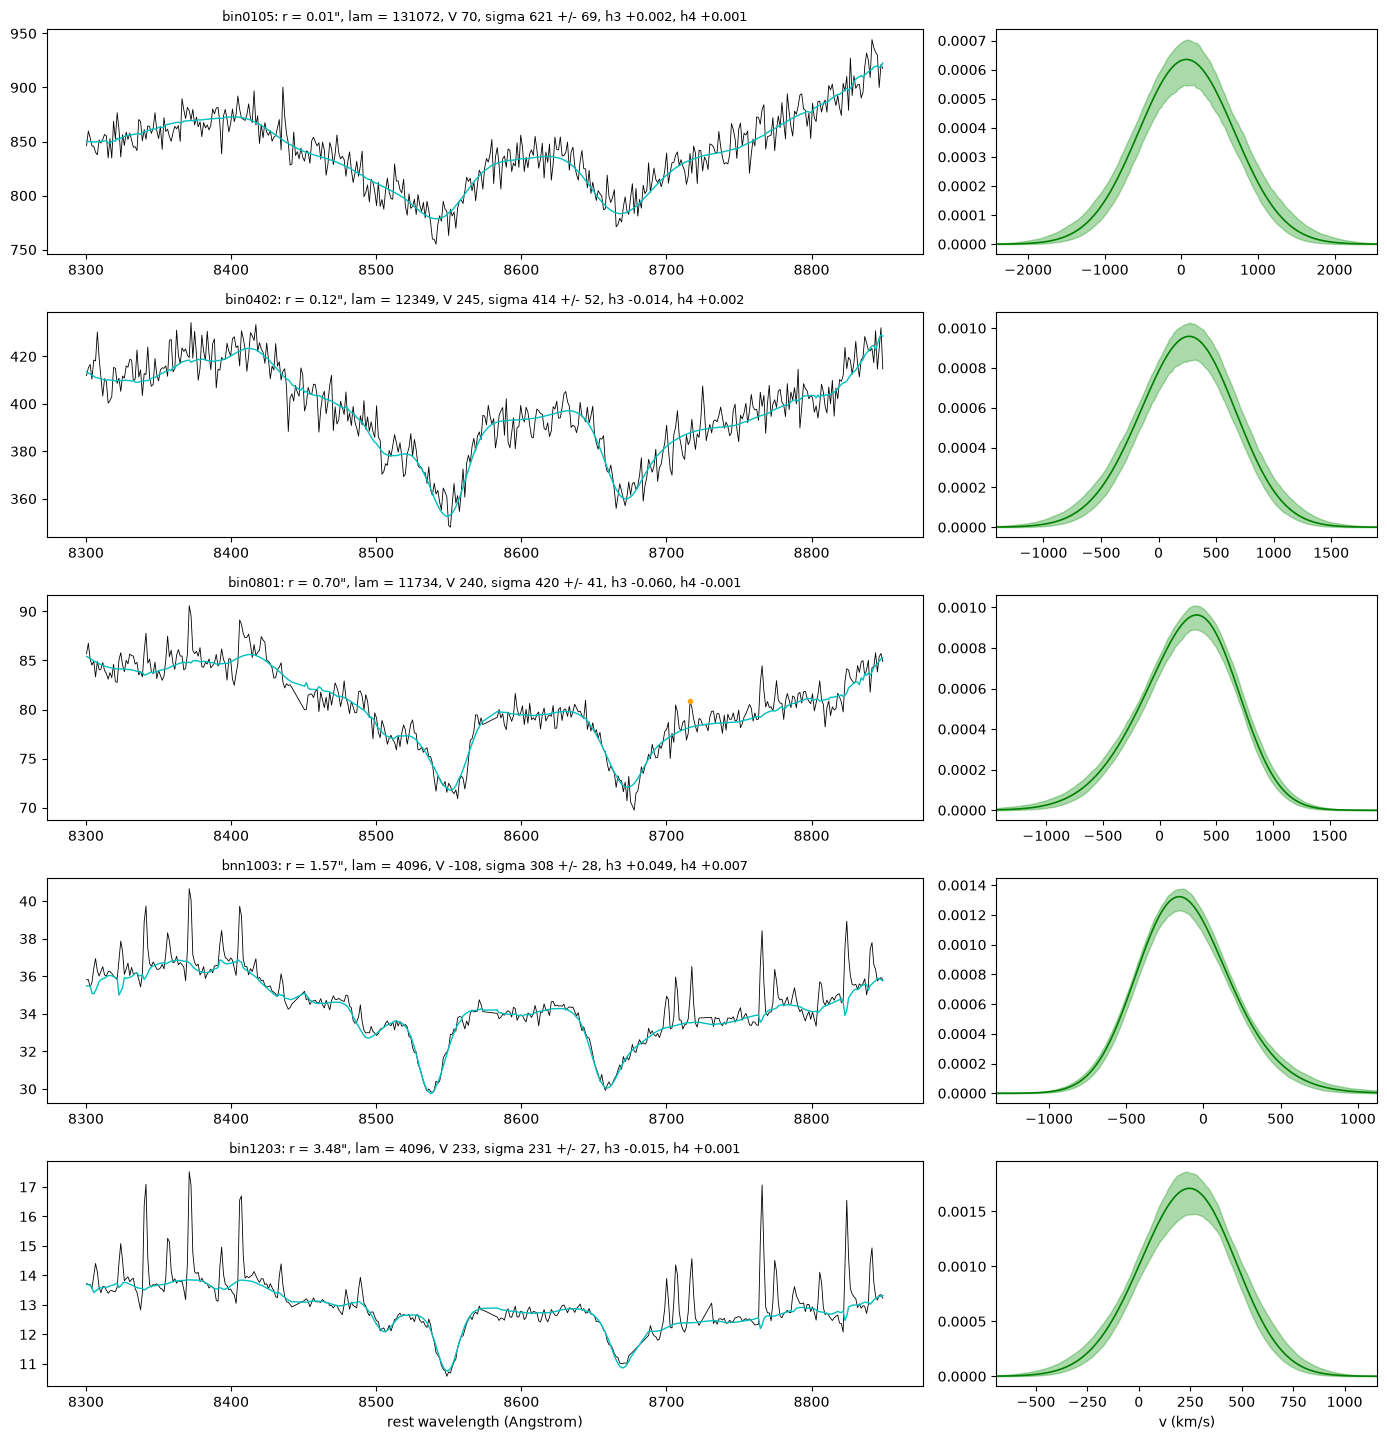

In [8]:
EXAMPLES = ["bin0105", "bin0402", "bin0801", "bnn1003", "bin1203"]
if not USE_SHIPPED:
    ex = {}
    for b in bins:
        if b["bin_name"] in EXAMPLES:
            cfg = cfg_for(b["fit"]["rho_used"], b["fit"]["lam_used"])
            A = build_template_stack(b["wave"], twave, templates, V_GRID)
            A_w, _, L = whiten(A, b["flux"], b["fit"]["errors_inflated"], rho=cfg.rho)
            ex[b["bin_name"]] = dict(wave=b["wave"], flux=b["flux"], model=L @ full_pixel_model(b["fit"], A_w, b["wave"], cfg),
                                     clipped=b["fit"]["clipped_mask"], b=b["fit"]["b"] / np.trapezoid(b["fit"]["b"], V_GRID),
                                     p16=b["band"]["b_p16"], p84=b["band"]["b_p84"])
else:
    ex = {n: {k: S[f"ex_{k}"][i][: int(S["ex_npix"][i])] if k in ("wave", "flux", "model", "clipped") else S[f"ex_{k}"][i]
              for k in ("wave", "flux", "model", "clipped", "b", "p16", "p84")} for i, n in enumerate(S["ex_name"])}
fig, axes = plt.subplots(len(EXAMPLES), 2, figsize=(14, 2.9 * len(EXAMPLES)), gridspec_kw=dict(width_ratios=(2.3, 1)))
for (a0, a1), n in zip(axes, EXAMPLES):
    e, i = ex[n], int(np.flatnonzero(kin["bin_name"] == n)[0])
    a0.plot(e["wave"], e["flux"], "k", lw=0.6); a0.plot(e["wave"], e["model"], "c", lw=1.0)
    a0.plot(e["wave"][e["clipped"]], e["flux"][e["clipped"]], "o", color="orange", ms=3)
    a0.set_title(f"{n}: r = {kin['r_mid'][i]:.2f}\", lam = {kin['lam'][i]:.0f}, V {kin['V'][i]:.0f}, "
                 f"sigma {kin['sigma'][i]:.0f} +/- {kin['esigma'][i]:.0f}, h3 {kin['h3'][i]:+.3f}, h4 {kin['h4'][i]:+.3f}", fontsize=9)
    a1.fill_between(V_GRID, e["p16"], e["p84"], color="tab:green", alpha=0.4); a1.plot(V_GRID, e["b"], "g", lw=1.2)
    a1.set_xlim(kin["V"][i] - 4 * kin["sigma"][i], kin["V"][i] + 4 * kin["sigma"][i])
axes[-1, 0].set_xlabel("rest wavelength (Angstrom)"); axes[-1, 1].set_xlabel("v (km/s)")
plt.tight_layout(); plt.show()

## 7. Systemic velocity

V_sys is the median midpoint velocity of the bin/bnn pairs. The two bins of a pair sit on opposite sides of the
minor axis at the same radius, so rotation cancels in their mean.

In [9]:
idx = {n: i for i, n in enumerate(kin["bin_name"])}
mid = [0.5 * (kin["V"][i] + kin["V"][idx["bnn" + n[3:]]]) for n, i in idx.items()
       if n.startswith("bin") and "bnn" + n[3:] in idx and kept[i] and kept[idx["bnn" + n[3:]]]]
V_SYS = float(np.median(mid))
print(f"V_sys = {V_SYS:+.2f} km/s from {len(mid)} pairs (16-84 %: {np.percentile(mid, 16):.1f} to {np.percentile(mid, 84):.1f})")

V_sys = +47.33 km/s from 48 pairs (16-84 %: 31.0 to 65.2)


## 8. Moment maps and radial profiles

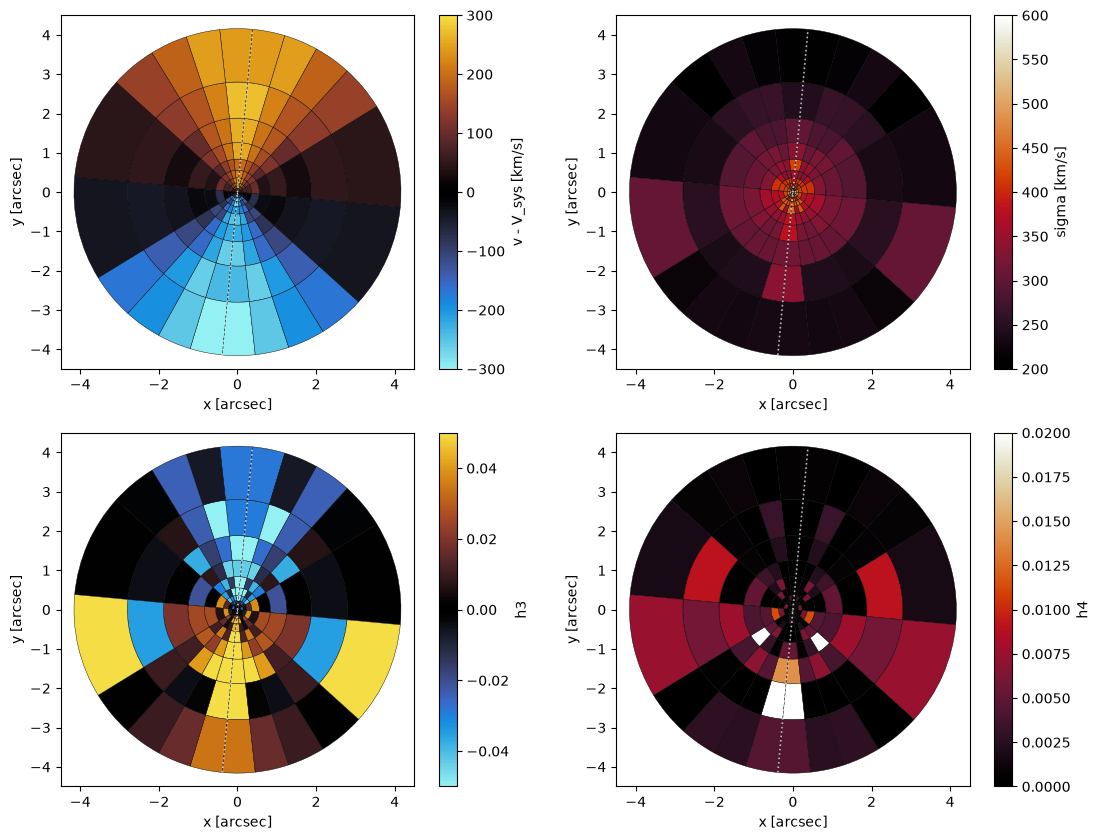

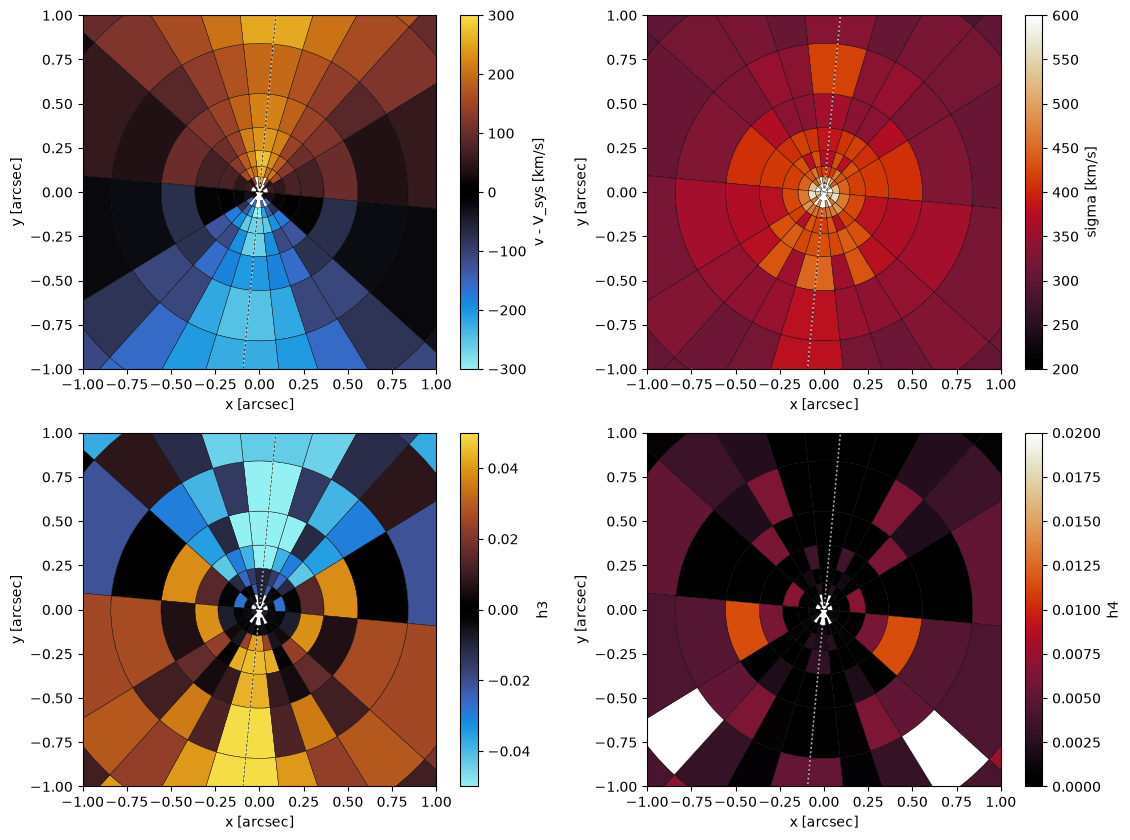

In [10]:
rows = [r for r in table if kept[idx[r["bin_name"]]]]
h3_plot = kin["h3"] - np.mean(kin["h3"][kept])
ICEBURN, SUNBURST = Colormap("cmasher:iceburn").to_mpl(), Colormap("cmasher:sunburst").to_mpl()
MAPS = [("V", kin["V"] - V_SYS, "v - V_sys [km/s]", ICEBURN, (-300, 300)),
        ("sigma", kin["sigma"], "sigma [km/s]", SUNBURST, (200, 600)),
        ("h3", h3_plot, "h3", ICEBURN, (-0.05, 0.05)),
        ("h4", kin["h4"], "h4", SUNBURST, (0.0, 0.02))]
for half_width in (4.5, 1.0):
    fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.5))
    for a, (key, vals, label, cm, lim) in zip(axes.ravel(), MAPS):
        norm = plt.Normalize(*lim)
        draw_bins(a, rows, {n: vals[i] for n, i in idx.items()}, cm, norm)
        plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cm), ax=a, fraction=0.046, label=label)
        a.set_xlim(-half_width, half_width); a.set_ylim(-half_width, half_width)
        a.set_xlabel("x [arcsec]"); a.set_ylabel("y [arcsec]")
    plt.tight_layout(); plt.show()

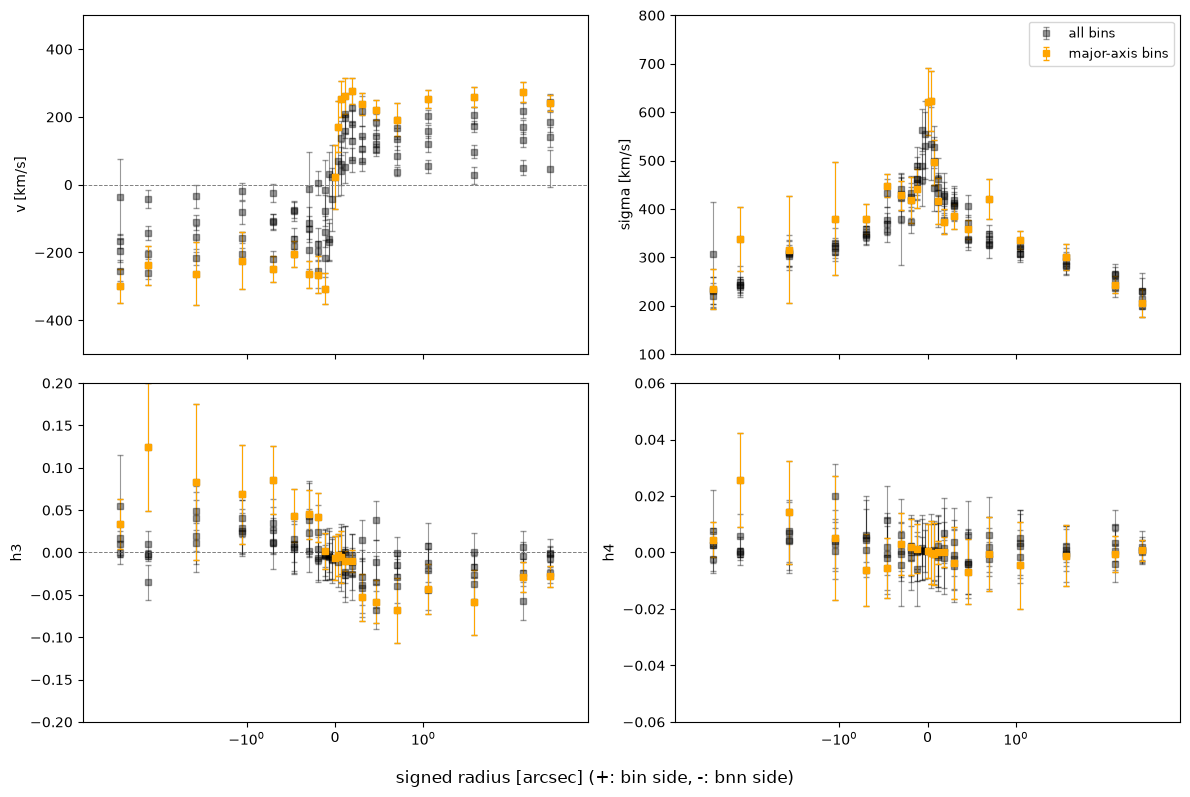

In [11]:
r_signed = np.where(kin["bin_name"] == "bin0105", 0.0, kin["side"] * kin["r_mid"])
kma = (kin["irv"] == 1) | (kin["bin_name"] == "bin0105")          # the kinematic-major-axis sector
PROFILES = [("V", kin["V"] - V_SYS, kin["eV"], "v [km/s]", (-500, 500)),
            ("sigma", kin["sigma"], kin["esigma"], "sigma [km/s]", (100, 800)),
            ("h3", h3_plot, kin["eh3"], "h3", (-0.2, 0.2)),
            ("h4", kin["h4"], kin["eh4"], "h4", (-0.06, 0.06))]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for a, (key, y, e, label, lim) in zip(axes.ravel(), PROFILES):
    s = kept
    a.errorbar(r_signed[s], y[s], yerr=e[s], fmt="s", color="k", ms=4, capsize=2, elinewidth=0.8, alpha=0.4, label="all bins")
    a.errorbar(r_signed[s & kma], y[s & kma], yerr=e[s & kma], fmt="s", color="orange", ms=5, capsize=2, elinewidth=0.8,
               label="major-axis bins")
    if key in ("V", "h3"):
        a.axhline(0, color="gray", lw=0.7, ls="--")
    a.set_ylabel(label); a.set_ylim(*lim)
axes[0, 1].legend(fontsize=9); axes[0, 0].set_xscale("symlog"); axes[0, 0].set_xlim(-6, 6)
fig.supxlabel("signed radius [arcsec] (+: bin side, -: bnn side)")
plt.tight_layout(); plt.show()

## 9. Mirror symmetry: are the errors honest?

In an axisymmetric galaxy a `bin` and its `bnn` mirror across the minor axis see the same LOSVD reflected in
velocity: V - V_sys and h3 change sign, sigma and h4 stay the same. Their differences, divided by the combined
errors, should then scatter with unit variance:
- **chi2 per pair and moment about 1:** the errors describe the bin-to-bin scatter.
- **Well above 1:** the errors are too small, or the galaxy (or the data) is not symmetric.
- **Somewhat below 1:** expected, because the template-mismatch part of the error is shared by both sides and cancels
  here. V_sys was also set from these pairs (Section 7), which lowers the V term a little.

In [12]:
sign = {"V": -1, "sigma": 1, "h3": -1, "h4": 1}       # mirror relation for (bnn) = sign * (bin)
err = {"V": "eV", "sigma": "esigma", "h3": "eh3", "h4": "eh4"}
pairs = [(idx[n], idx["bnn" + n[3:]]) for n in kin["bin_name"][kept]
         if n.startswith("bin") and "bnn" + n[3:] in idx and kept[idx["bnn" + n[3:]]]]
print(f"{len(pairs)} kept pairs; chi2 per pair (bin vs mirrored bnn)")
print("  radius [\"]      n    " + "".join(f"{m:>8s}" for m in sign))
for lo, hi in ((0.0, 0.55), (0.55, 1.6), (1.6, 5.0)):
    sel = [(a, b) for a, b in pairs if lo <= kin["r_mid"][a] < hi]
    row = []
    for m, sg in sign.items():
        x = kin[m] - (V_SYS if m == "V" else 0.0)
        d = np.array([x[a] - sg * x[b] for a, b in sel])
        e2 = np.array([kin[err[m]][a] ** 2 + kin[err[m]][b] ** 2 for a, b in sel])
        row.append(np.mean(d ** 2 / e2))
    print(f"  {lo:4.2f}-{hi:4.2f}  {len(sel):5d}    " + "".join(f"{c:8.2f}" for c in row))

48 kept pairs; chi2 per pair (bin vs mirrored bnn)
  radius ["]      n           V   sigma      h3      h4
  0.00-0.55     23        0.54    1.01    0.43    0.09
  0.55-1.60     15        0.43    0.47    0.62    0.19
  1.60-5.00     10        0.66    0.53    1.24    0.37


In [13]:
# Full run only: write the compact results this notebook reads by default.
if not USE_SHIPPED:
    order = [idx[r["bin_name"]] for r in table]
    tab = {k: np.asarray([r[k] for r in table]) for k in ("bin_id", "bin_name", "irc", "irv", "side")}
    tab["r_mid"] = np.abs([r["r_mid"] for r in table])
    names = [n for n in EXAMPLES if n in ex]
    npix = max(len(ex[n]["wave"]) for n in names)
    pad = lambda a, fill=np.nan: np.concatenate([a, np.full(npix - len(a), fill)])  # noqa: E731
    np.savez_compressed(
        RESULTS_PATH, white=white.astype(np.float32), mask=mask, bin_map=bin_map.astype(np.int16), pix=pix,
        **tab, **{k: kin[k][order] for k in ("n_spaxels", "lam", "edge", "inflation", "V", "sigma", "h3", "h4",
                                             "eV", "esigma", "eh3", "eh4")},
        ex_name=np.array(names), ex_npix=np.array([len(ex[n]["wave"]) for n in names]),
        **{f"ex_{k}": np.array([pad(ex[n][k]) for n in names]) for k in ("wave", "flux", "model")},
        ex_clipped=np.array([pad(ex[n]["clipped"], False).astype(bool) for n in names]),
        **{f"ex_{k}": np.array([ex[n][k] for n in names]) for k in ("b", "p16", "p84")})
    print(f"saved {RESULTS_PATH} ({RESULTS_PATH.stat().st_size / 1e6:.1f} MB)")

## Conclusion

This notebook ran a whole extraction on a real cube:
1. masking, including defective spaxels the cube does not flag;
2. a legacy dartboard folded about the major axis;
3. fits with the package defaults: a fixed `lam`, raised for broad bins (`sigma_scaled_lam`);
4. error bands from the sky-line + template-mismatch noise model, re-centered on the fits;
5. moment maps, radial profiles and a mirror-symmetry check of the errors.

**Checks worth making on any data set:**
- The mirror-pair chi2 should be about 1 or below, in every radial range.
- Flagged bins deserve a look at their spectra (Section 6) before they are approved or rejected.
- The noise-model inflation should be modest. Large values mean the residuals are dominated by sky lines or template
  mismatch, and the bin will carry little weight.

**What is not here:**
- **Template error:** refitting with alternative template sets and adding their spread in quadrature (template
  mismatch is the largest remaining bias at high S/N).
- **Other data sets:** combining cubes of different resolution (e.g. MUSE WFM and NFM) needs a common V_sys.

The settings come from the tests in `dev_notes/regularization_v2/FINDINGS.md`.